**과제 (강의자료 Ch4 p40, Homework)**
- Read chapter 4
- Exercise 4.7 (programming): Jack's car rental 변형 문제를 정책 반복으로 풀기
- Exercise 4.8: Gambler 최적 정책의 모양 설명
- Exercise 4.9 (programming): Gambler's problem을 $p_h=0.25,\ 0.55$로 풀기
- 질문: 정책 반복과 가치 반복의 차이는? 왜 Jack's는 PI 절에, Gambler는 VI 절에 있는가?

In [2]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson
os.makedirs('figures', exist_ok=True)

**Exercise 4.7**: Jack's Car Rental 변형

1. 지점1 직원이 퇴근길에 1대를 지점2로 무료로 옮겨준다 ; 1→2 방향으로 $a>0$대 이동 시 비용 $2(a-1)$, 2→1 방향은 그대로 $2|a|$.
2. 이동 후 한 지점에 10대 초과로 밤을 보내면 추가 주차장 비용 \$4 (지점마다, 대수와 무관).

**구현 방법** 
- 상태 $s=(n_1,n_2)$, 행동 $a\in[-5,5]$ (양수 = 1→2로 이동).
- 기대 보상과 전이 확률을 미리 계산해 둔다. 두 지점의 대여·반납은 서로 독립이므로 전이 확률이 지점별로 분리된다:
$$p(n_1',n_2'\mid \tilde n_1,\tilde n_2)=P_1(n_1'\mid \tilde n_1)\,P_2(n_2'\mid \tilde n_2)$$
($\tilde n$ = 이동 후 대수)

In [3]:
MAX_CARS, MAX_MOVE = 20, 5
REQ1, REQ2, RET1, RET2 = 3, 4, 3, 2
GAMMA, RENTAL_CREDIT, MOVE_COST = 0.9, 10, 2
PARKING_LIMIT, PARKING_COST = 10, 4
UPPER = 11                    

def location_model(req_lam, ret_lam):
    # 한 지점의 (기대 대여 수익, 다음 날 대수 전이 확률) 사전 계산
    exp_reward = np.zeros(MAX_CARS + 1)
    trans = np.zeros((MAX_CARS + 1, MAX_CARS + 1))
    for cars in range(MAX_CARS + 1):
        for req in range(UPPER):
            p_req = poisson.pmf(req, req_lam)
            rent = min(cars, req)
            exp_reward[cars] += p_req * rent * RENTAL_CREDIT
            for ret in range(UPPER):
                p_ret = poisson.pmf(ret, ret_lam)
                trans[cars, min(cars - rent + ret, MAX_CARS)] += p_req * p_ret
    return exp_reward, trans

R1, P1 = location_model(REQ1, RET1)
R2, P2 = location_model(REQ2, RET2)

def action_cost(action, n1, n2, modified):
    # 이동 비용 + 주차 비용. n1, n2는 이동 후 대수
    if modified and action > 0:
        cost = MOVE_COST * (action - 1)          # 1대는 직원이 무료로 운반
    else:
        cost = MOVE_COST * abs(action)
    if modified:
        cost += PARKING_COST * (n1 > PARKING_LIMIT) + PARKING_COST * (n2 > PARKING_LIMIT)
    return cost

def expected_return(state, action, V, modified):
    n1, n2 = state[0] - action, state[1] + action          # 이동 후 대수
    r = R1[n1] + R2[n2] - action_cost(action, n1, n2, modified)
    return r + GAMMA * P1[n1] @ V @ P2[n2]                 # = sum p(s'|s,a) V(s')

def valid_actions(i, j):
    return range(max(-MAX_MOVE, -j, -(MAX_CARS - i)), min(MAX_MOVE, i, MAX_CARS - j) + 1)

**정책 반복** (교재 p.80 의사코드)
1. 정책 평가: 현재 정책 π로 $V$가 수렴할 때까지 in-place sweep
2. 정책 개선: 각 상태에서 $\arg\max_a$ 기댓값으로 정책 교체
3. 정책이 더 이상 바뀌지 않으면 종료

Exercise 4.4의 버그(동점 행동 사이를 무한히 오가는 문제)를 막기 위해 새 행동이 기존 행동보다 `1e-8` 이상 좋을 때만 정책을 바꾼다.

In [4]:
def policy_iteration(modified, theta=1e-4):
    policy = np.zeros((MAX_CARS + 1, MAX_CARS + 1), dtype=int)
    V = np.zeros((MAX_CARS + 1, MAX_CARS + 1))
    history, sweeps = [policy.copy()], 0
    while True:
        # 1) policy evaluation
        while True:
            delta = 0.0
            for i in range(MAX_CARS + 1):
                for j in range(MAX_CARS + 1):
                    v_old = V[i, j]
                    V[i, j] = expected_return((i, j), policy[i, j], V, modified)
                    delta = max(delta, abs(v_old - V[i, j]))
            sweeps += 1
            if delta < theta:
                break
        # 2) policy improvement
        stable = True
        for i in range(MAX_CARS + 1):
            for j in range(MAX_CARS + 1):
                old = policy[i, j]
                best_a, best_v = old, expected_return((i, j), old, V, modified)
                for a in valid_actions(i, j):
                    v = expected_return((i, j), a, V, modified)
                    if v > best_v + 1e-8:          # Ex 4.4: 진짜로 더 좋을 때만 교체
                        best_a, best_v = a, v
                policy[i, j] = best_a
                if best_a != old:
                    stable = False
        history.append(policy.copy())
        if stable:
            return policy, V, history, sweeps

results = {}
for modified in [False, True]:
    t0 = time.time()
    results[modified] = policy_iteration(modified)
    pol, V, hist, sweeps = results[modified]
    name = 'Exercise 4.7 (modified)' if modified else 'Example 4.2 (original)'
    print(f'{name:25s}: {len(hist)-1} policy improvements, {sweeps} evaluation sweeps, '
          f'{time.time()-t0:.1f}s, V range [{V.min():.1f}, {V.max():.1f}]')

Example 4.2 (original)   : 5 policy improvements, 206 evaluation sweeps, 0.4s, V range [406.1, 617.9]
Exercise 4.7 (modified)  : 4 policy improvements, 203 evaluation sweeps, 0.5s, V range [414.3, 584.2]


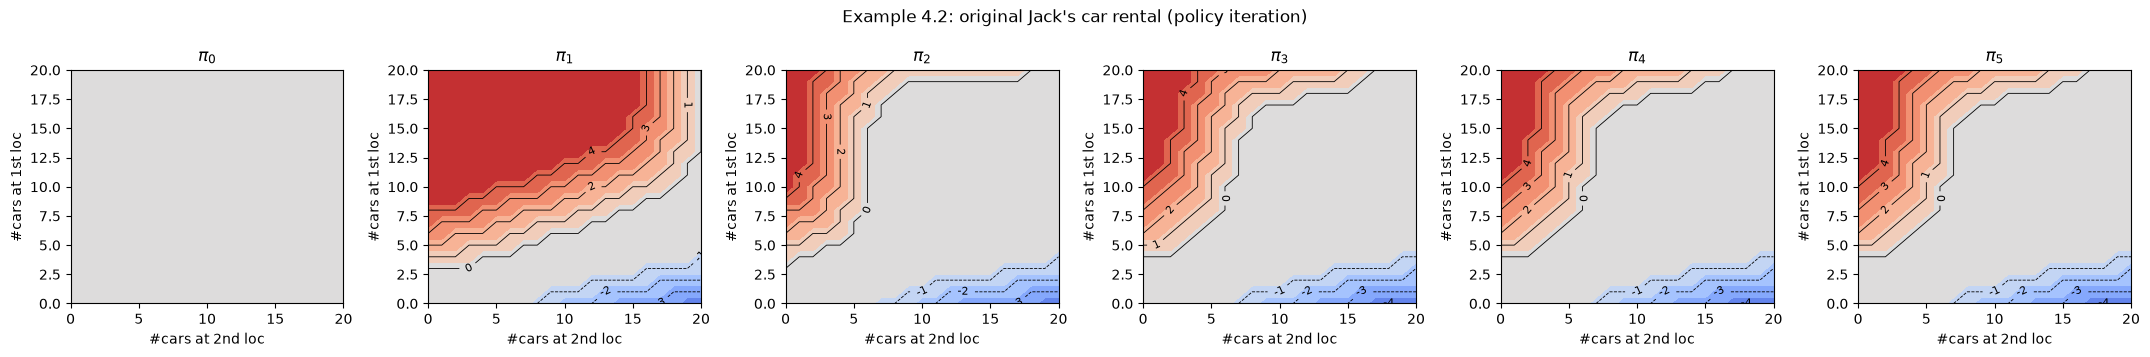

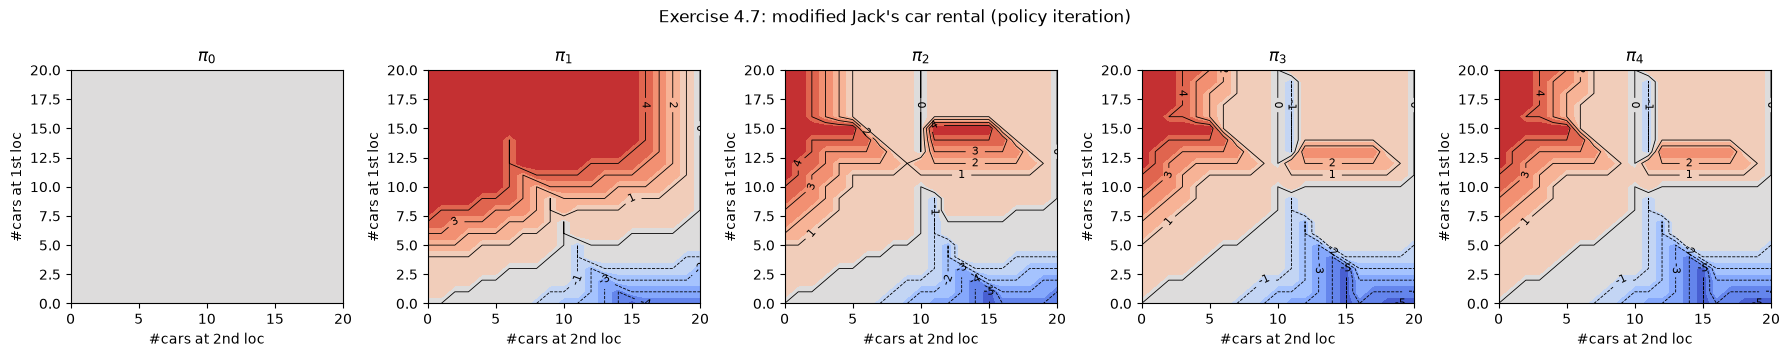

In [5]:
def plot_policies(history, title, fname):
    n = len(history)
    cols = min(n, 6)
    fig, axes = plt.subplots(1, cols, figsize=(3.6 * cols, 3.6))
    idxs = list(range(n)) if n <= 6 else list(range(5)) + [n - 1]
    for ax, k in zip(np.atleast_1d(axes), idxs):
        pol = history[k]
        ax.contourf(pol, levels=np.arange(-5.5, 6.5, 1), cmap='coolwarm')
        cl = ax.contour(pol, levels=np.arange(-5, 6, 1), colors='k', linewidths=0.6)
        ax.clabel(cl, inline=True, fontsize=8, fmt='%d')
        ax.set_title(rf'$\pi_{{{k}}}$')
        ax.set_xlabel('#cars at 2nd loc'); ax.set_ylabel('#cars at 1st loc')
    fig.suptitle(title)
    plt.tight_layout(); plt.savefig(fname, dpi=130); plt.show()

plot_policies(results[False][2], "Example 4.2: original Jack's car rental (policy iteration)", 'figures/jacks_original_policies.png')
plot_policies(results[True][2],  "Exercise 4.7: modified Jack's car rental (policy iteration)", 'figures/jacks_modified_policies.png')

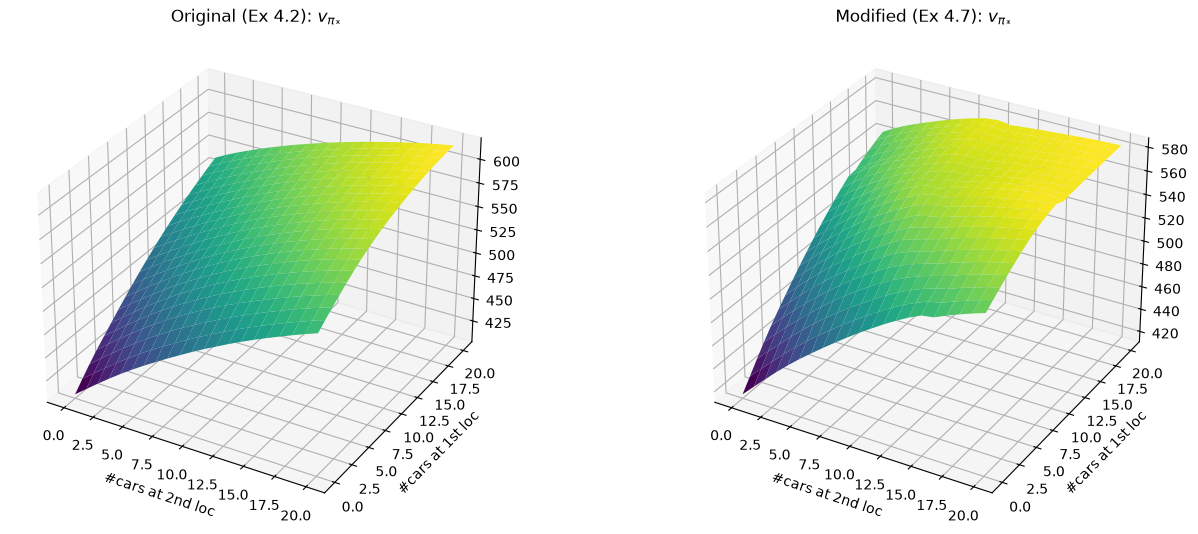

states where the optimal action changed: 238 / 441
policy pi*(s1, s2) for s1 = 20..10 (rows), s2 = 0..10 (cols), modified problem:
[[5 5 5 4 4 3 2 1 1 1 0]
 [5 5 5 4 3 3 2 1 1 1 0]
 [5 5 5 4 3 2 2 1 1 1 0]
 [5 5 5 4 3 2 1 1 1 1 0]
 [5 5 4 4 3 2 1 1 1 1 0]
 [5 5 5 5 5 5 1 1 1 1 0]
 [5 5 4 4 4 4 4 1 1 1 0]
 [5 4 4 3 3 3 3 3 1 1 0]
 [5 4 3 3 2 2 2 2 2 1 0]
 [4 4 3 2 2 1 1 1 1 1 1]
 [4 3 3 2 1 1 1 1 1 1 0]]


In [6]:
fig = plt.figure(figsize=(14, 5.5))
X, Y = np.meshgrid(np.arange(MAX_CARS + 1), np.arange(MAX_CARS + 1))
for k, modified in enumerate([False, True]):
    ax = fig.add_subplot(1, 2, k + 1, projection='3d')
    ax.plot_surface(X, Y, results[modified][1], cmap='viridis', edgecolor='none')
    ax.set_title(('Modified (Ex 4.7)' if modified else 'Original (Ex 4.2)') + r': $v_{\pi_*}$')
    ax.set_xlabel('#cars at 2nd loc'); ax.set_ylabel('#cars at 1st loc')
plt.tight_layout(); plt.savefig('figures/jacks_values_3d.png', dpi=130); plt.show()

pol_o, pol_m = results[False][0], results[True][0]
diff = pol_m - pol_o
print('states where the optimal action changed:', int((diff != 0).sum()), '/ 441')
print('policy pi*(s1, s2) for s1 = 20..10 (rows), s2 = 0..10 (cols), modified problem:')
print(pol_m[20:9:-1, :11])

**표 해석** 

Ex 4.7: 4번 개선 후 수렴했다. 441개 상태 중 238개에서 최적 행동이 바뀌었다. 바뀐 특징은 규칙과 정확히 대응한다.
- 무료 셔틀 1대 ; 원래 정책에서 0대 이동이던 넓은 영역(회색)이 +1대 이동(주황)으로 바뀌었다; 1대 옮기는 비용이 0이니, 지점2로 1대를 보내는 것이 거의 항상 이득이기 때문.
- 주차 한도 10대 ; 비교적 평평하던 4.2와 다르게 정책 그래프에 10대 근처를 경계로 꺽인다. 지점1에 11–15대 있을 때는 대수를 10 이하로 맞추기 위해 더 많이 옮기고, 지점2가 10대 이하일 때는 지점2가 10대를 넘지 않도록 이동을 멈춘다. 지점2에 11대 이상일 때는 오히려 지점1로 차를 되돌리는 영역(파랑)이 커졌다.

---

**Exercise 4.8**:

- 이 문제에서 앞면이 나올 확률은 $p_h=0.4$로 0.5보다 작아서 도박사에게 불리한 게임이다. 베팅 횟수가 많아질수록 질 확률이 계속 쌓이므로, 가능한 적은 횟수로 목표에 도달하는 것이 유리하다.
- 자본이 50일 때는 전부 걸면 한 번 이기는 것만으로 바로 100에 도달할 수 있다. 이때 성공 확률은 0.4이고, 이것보다 적게 걸면 여러 번 이겨야 하므로 성공 확률이 더 낮아진다. 그래서 50에서는 전부 거는 것이 최적이다.
- 자본이 51일 때 51을 모두 걸 필요는 없다. 이기더라도 100을 넘는 돈은 의미가 없기 때문이다. 대신 1만 걸면 이겼을 때는 52가 되어 상황이 좋아지고, 졌을 때는 50이 되어 다시 50을 모두 거는 전략으로 0.4의 확률을 그대로 가질 수 있다. 그래서 극단 적으로 내려가서 톱니 모양이 되는 것이다; 같은 이유로 25, 75 중심으로 반복되는 톱니 모양이 된다.

---

**Exercise 4.9**: Gambler's Problem ($p_h$ = 0.25, 0.55)

**구현 방법**: 

- 종료 상태 0과 100을 더미 상태로 두고 $V(0)=0,\ V(100)=1$로 고정. <100에 도달하면 보상 +1> 을 따로 처리할 필요 없이 $V(s)$가 곧 이길 확률이 된다.
$$V(s)\leftarrow\max_{a\in\{1,\dots,\min(s,100-s)\}}\big[p_h V(s+a)+(1-p_h)V(s-a)\big]$$
최종 정책은 argmax 중 동점(1e-9 이내)이면 가장 작은 판돈을 고른다 (교재 Figure 4.3과 같은 규칙).

p_h=0.25: 19 sweeps, V(25)=0.0625, V(50)=0.2500, V(75)=0.4375, stake at 50 = 50, #states with stake 1 = 8/99
p_h=0.4: 22 sweeps, V(25)=0.1600, V(50)=0.4000, V(75)=0.6400, stake at 50 = 50, #states with stake 1 = 8/99
p_h=0.55: 2256 sweeps, V(25)=0.9934, V(50)=1.0000, V(75)=1.0000, stake at 50 = 1, #states with stake 1 = 99/99


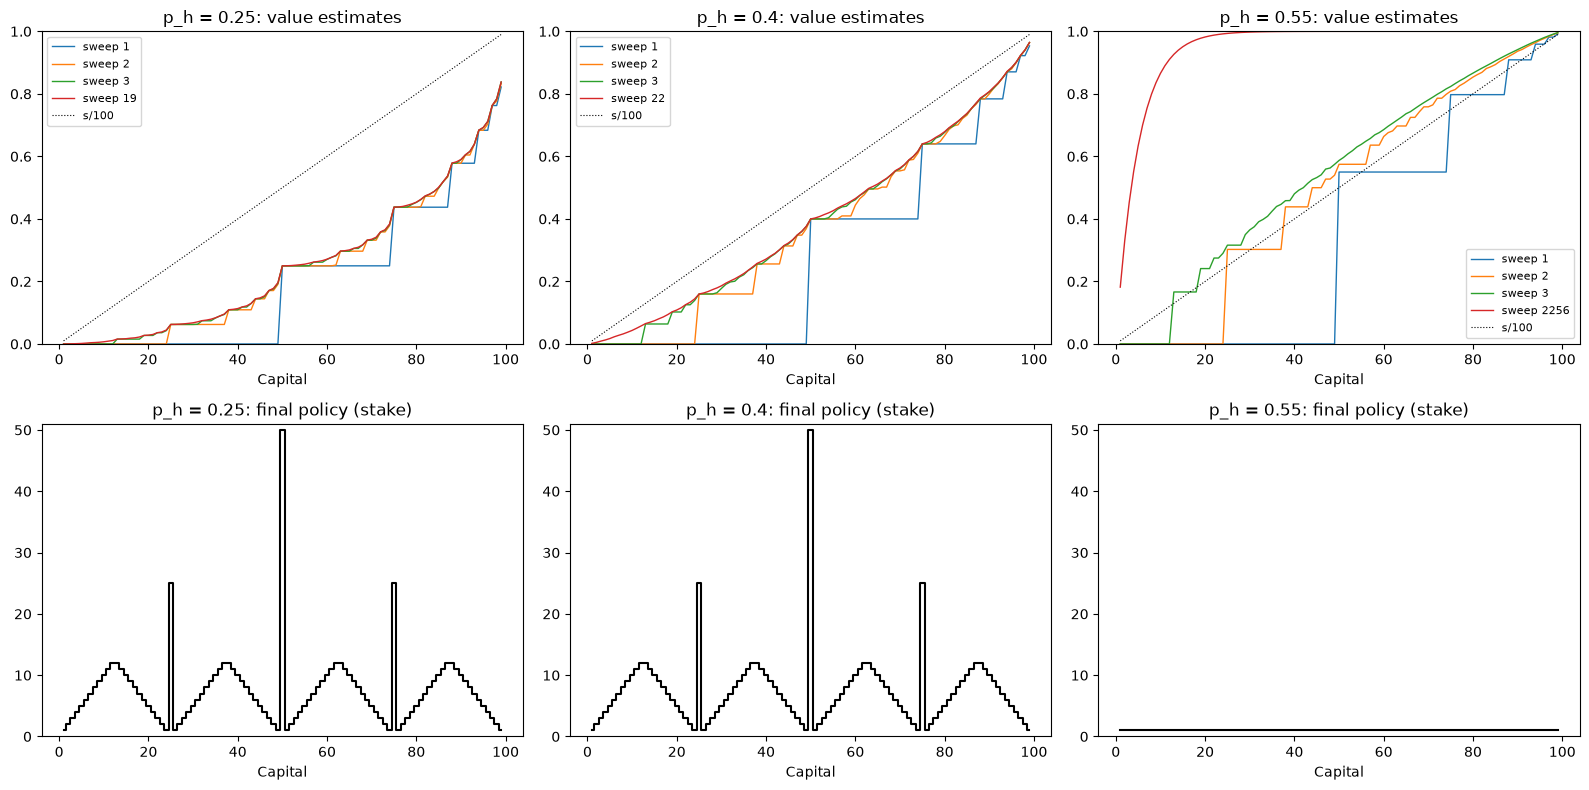

In [7]:
GOAL = 100

def solve_gambler(p_h, theta=1e-12, record=(1, 2, 3)):
    V = np.zeros(GOAL + 1); V[GOAL] = 1.0
    history, sweep = {}, 0
    while True:
        sweep += 1
        delta = 0.0
        for s in range(1, GOAL):
            stakes = np.arange(1, min(s, GOAL - s) + 1)
            best = np.max(p_h * V[s + stakes] + (1 - p_h) * V[s - stakes])
            delta = max(delta, abs(best - V[s])); V[s] = best
        if sweep in record:
            history[sweep] = V.copy()
        if delta < theta:
            history[sweep] = V.copy()
            break
    policy = np.zeros(GOAL + 1, dtype=int)
    for s in range(1, GOAL):
        stakes = np.arange(1, min(s, GOAL - s) + 1)
        q = p_h * V[s + stakes] + (1 - p_h) * V[s - stakes]
        policy[s] = stakes[np.flatnonzero(q >= q.max() - 1e-9)[0]]
    return V, policy, history, sweep

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
caps = np.arange(1, GOAL)
for k, p_h in enumerate([0.25, 0.4, 0.55]):
    V, pol, hist, n_sweeps = solve_gambler(p_h)
    for sw, Vs in hist.items():
        axes[0, k].plot(caps, Vs[1:GOAL], lw=1, label=f'sweep {sw}')
    axes[0, k].plot(caps, caps / 100, 'k:', lw=0.8, label='s/100')
    axes[0, k].set_title(f'p_h = {p_h}: value estimates'); axes[0, k].legend(fontsize=8)
    axes[0, k].set_xlabel('Capital'); axes[0, k].set_ylim(0, 1)
    axes[1, k].step(caps, pol[1:GOAL], where='mid', color='k')
    axes[1, k].set_title(f'p_h = {p_h}: final policy (stake)')
    axes[1, k].set_xlabel('Capital'); axes[1, k].set_ylim(0, 51)
    print(f'p_h={p_h}: {n_sweeps} sweeps, V(25)={V[25]:.4f}, V(50)={V[50]:.4f}, V(75)={V[75]:.4f}, '
          f'stake at 50 = {pol[50]}, #states with stake 1 = {(pol[1:GOAL] == 1).sum()}/99')
plt.tight_layout(); plt.savefig('figures/gambler_ph.png', dpi=130); plt.show()

**결과 해석**

1. 불리한 게임 ($p_h<0.5$): 크게 배팅하고, 빨리 끝낸다

$p_h=0.25$일 때 최적 정책은 $p_h=0.4$(교재 Figure 4.3)와 같은 톱니 모양이다. 25, 50, 75에서 크게 걸어 한 번에 다음 단계로 넘어가려 한다. 한 판마다 질 확률이 더 크기 때문에 판수를 줄이는 것이 유리하다.

2. 유리한 게임 ($p_h>0.5$): 조금씩 배팅하고, 오래 한다

$p_h=0.55$에서는 모든 상태에서 1씩만 거는 정책이 최적으로 나왔다. 매 판이 나에게 유리하므로 판을 많이 할수록 돈이 늘어나고, 한 번에 크게 잃을 위험은 피할 수 있다. 자본이 25만 되어도 성공 확률이 0.99 이상이다.

3. 수렴 속도

$p_h=0.55$는 2256 sweep, 나머지는 20번 정도로 차이가 크다; 1씩 거는 정책에서는 한 sweep마다 가치 정보가 이웃 상태로 한 칸씩만 전달되어 정보가 퍼지는 데 오래 걸리지만, 크게 거는 정책에서는 100의 정보가 몇 번 만에 50, 25까지 전달되기 때문이다.

---

1. 정책 반복과 가치 반복의 차이는?

정책 반복은 평가를 끝까지 하고 개선, 가치 반복은 평가를 한 번만 하고 바로 개선한다. 그래서 정책 반복은 적게 반복하지만 한 번이 무겁고, 가치 반복은 한 번이 가볍지만 많이 반복한다.

2. 왜 Jack's 문제는 정책 반복 절에, Gambler's 문제는 가치 반복 절에 있는가?

Jack's 문제는 -차를 옮기지 않는다-는 자연스러운 초기 정책이 있고 할인율 $\gamma=0.9$인 연속 과제라 정책 평가가 안정적이며, 정책이 상대적으로 적게 바뀌고 수렴해 정책 반복의 장점을 보여주기 좋다. 반면 Gambler's 문제는 할인이 없는($\gamma=1$) 에피소딕 과제라 정책에 따라 평가가 매우 느려지고, 관심 대상이 이길 확률인 가치 함수 자체이며 최적 정책도 하나로 정해지지 않아 가치를 직접 반복하는 가치 반복이 더 자연스럽다. 즉 두 문제 각 각 방법의 특징을 가장 잘 보여주는 예제가 들어간 것이다.